# Data integrity EDA (customers / orders / labels)

**Purpose:** find data-integrity problems that the cleaning pipeline has to handle.

**Reusable on new data:** every check is driven by the **Config** cell. To run it on a new drop:
1. Point `DATA_DIR` at the new folder, or set the env var `EDA_DATA_DIR`.
2. Run all cells. Every finding goes into one `issues` table, which is saved to `OUTPUT_DIR`.
3. If a baseline profile exists (made from the base sample), section 13 lists **drift** against it:
   new categories, shifted missing-value rates, shifted numeric ranges.

All files are read **as raw strings** so that formatting problems are seen *before* any type conversion hides them.

| Severity | Meaning |
|---|---|
| `error` | breaks a hard rule (schema, key, type, allowed values). The pipeline must fix it or reject the row |
| `warning` | suspicious or inconsistent. The pipeline needs a rule decided for it |
| `info` | something to know when designing the pipeline (coverage, representation) |

In [1]:
import csv
import difflib
import json
import os
import re
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

## 0. Config
Edit this cell when the schema or the business rules change. Column `kind`s: `id`, `category`, `bool`, `int`, `float`, `datetime`.

In [2]:
DATA_DIR = Path(os.environ.get("EDA_DATA_DIR", "../data"))
OUTPUT_DIR = Path(os.environ.get("EDA_OUTPUT_DIR", "../eda_output"))
RUN_TAG = os.environ.get("EDA_RUN_TAG", datetime.now().strftime("%Y%m%d_%H%M%S"))

# Profile of the reference dataset used for drift checks (section 13).
BASELINE_PROFILE = OUTPUT_DIR / "baseline_profile.json"
# True -> this run's profile becomes the baseline. Leave False for new data.
SAVE_AS_BASELINE = os.environ.get("EDA_SAVE_AS_BASELINE", "0") == "1" or not BASELINE_PROFILE.exists()

# Strings (case-insensitive, after strip) treated as missing.
NULL_TOKENS = {"", "nan", "null", "none", "n/a", "na", "-", "?", "nat", "missing"}

COUNTRIES = ["BD", "MY", "PH", "PK", "TH"]
ID_PATTERN = r"^[0-9a-f]{10}$"

# Formats tried on date values that do not match the expected format, to see what else turns up.
CANDIDATE_DATE_FORMATS = [
    "%Y-%m-%d %H:%M:%S", "%Y-%m-%d", "%Y/%m/%d", "%Y/%m/%d %H:%M:%S", "%Y/%b/%d", "%Y-%b-%d",
    "%d/%m/%Y", "%m/%d/%Y", "%d-%m-%Y", "%Y%m%d", "%d %b %Y", "%Y-%m-%dT%H:%M:%S",
]
MIN_PLAUSIBLE_DATE = pd.Timestamp("2005-01-01")
MAX_PLAUSIBLE_DATE = pd.Timestamp.now().normalize() + pd.Timedelta(days=1)

TABLES = {
    "customers": {
        "file": "customers_base.csv",
        "primary_key": ["customer_id"],
        "columns": {
            "country_code": {"kind": "category", "allowed": COUNTRIES, "nullable": False},
            "customer_id": {"kind": "id", "pattern": ID_PATTERN, "nullable": False},
            "mobile_verified": {"kind": "bool", "true": ["True"], "false": ["False"], "nullable": False},
            "num_orders_last_50days": {"kind": "int", "min": 0, "nullable": False},
            "num_cancelled_orders_last_50days": {"kind": "int", "min": 0, "nullable": False},
            "num_refund_orders_last_50days": {"kind": "int", "min": 0, "nullable": False},
            "total_payment_last_50days": {"kind": "float", "min": 0, "nullable": False},
            "num_associated_customers": {"kind": "int", "min": 1, "nullable": False},
            "first_order_datetime": {"kind": "datetime", "format": "%Y-%m-%d %H:%M:%S", "nullable": False},
        },
    },
    "orders": {
        "file": "orders_base.csv",
        "primary_key": ["order_id"],
        "columns": {
            "country_code": {"kind": "category", "allowed": COUNTRIES, "nullable": False},
            "order_id": {"kind": "id", "pattern": ID_PATTERN, "nullable": False},
            # Canonical casing is assumed. Confirm it with the data owner.
            "collect_type": {"kind": "category", "allowed": ["Delivery", "Pickup"], "nullable": False},
            # allowed=None -> no fixed list. The case-variant / near-duplicate checks still run.
            "payment_method": {"kind": "category", "allowed": None, "nullable": False},
            "order_value": {"kind": "float", "min": 0, "nullable": False},
            "num_items_ordered": {"kind": "int", "min": 1, "nullable": False},
            "refund_value": {"kind": "float", "min": 0, "nullable": False},
            "order_date": {"kind": "datetime", "format": "%Y/%m/%d", "nullable": False, "daily_continuity": True},
        },
    },
    "labels": {
        "file": "labels_base.csv",
        "primary_key": ["order_id"],
        "columns": {
            "country_code": {"kind": "category", "allowed": COUNTRIES, "nullable": False},
            "order_id": {"kind": "id", "pattern": ID_PATTERN, "nullable": False},
            "customer_id": {"kind": "id", "pattern": ID_PATTERN, "nullable": False},
            "is_fraud": {"kind": "category", "allowed": ["0", "1"], "nullable": False},
        },
    },
}

# child_table.child_col -> parent_table.parent_col; `compare` = columns that must agree across the join.
FOREIGN_KEYS = [
    {"child": "labels", "child_col": "order_id", "parent": "orders", "parent_col": "order_id", "compare": ["country_code"]},
    {"child": "labels", "child_col": "customer_id", "parent": "customers", "parent_col": "customer_id", "compare": ["country_code"]},
]
# Coverage checks run the other way: should every parent row have a child row?
COVERAGE = [
    {"parent": "orders", "parent_col": "order_id", "child": "labels", "child_col": "order_id", "expected_full": True},
    {"parent": "customers", "parent_col": "customer_id", "child": "labels", "child_col": "customer_id", "expected_full": False},
]
# Column used to group systematic-missingness checks (section 12).
GROUP_COL = "country_code"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("DATA_DIR =", DATA_DIR.resolve())
print("OUTPUT_DIR =", OUTPUT_DIR.resolve(), "| RUN_TAG =", RUN_TAG, "| SAVE_AS_BASELINE =", SAVE_AS_BASELINE)

DATA_DIR = /filepool/Documents/nilang/course/MLOPS/CA1/data
OUTPUT_DIR = /filepool/Documents/nilang/course/MLOPS/CA1/eda_output | RUN_TAG = 20261026_105627 | SAVE_AS_BASELINE = True


### Helpers

In [3]:
ISSUES = []

def log_issue(table, column, check, severity, n, total=None, examples=None, note=""):
    """Record one finding. Zero-count findings are skipped."""
    n = int(n)
    if n == 0:
        return
    if examples is not None:
        examples = ", ".join(repr(x.item() if isinstance(x, np.generic) else x)
                             for x in list(pd.unique(pd.Series(list(examples))))[:5])
    ISSUES.append({
        "table": table, "column": column, "check": check, "severity": severity,
        "n_rows": n, "pct": round(100 * n / total, 4) if total else None,
        "examples": examples or "", "note": note,
    })

def cols_of(table, kinds=None):
    """Columns from the config that are present in the loaded table, optionally filtered by kind."""
    spec = TABLES[table]["columns"]
    return [c for c, s in spec.items()
            if c in raw[table].columns and (kinds is None or s["kind"] in kinds)]

def is_null_token(s):
    return s.str.strip().str.lower().isin(NULL_TOKENS)

def issues_for(check_prefix):
    df = pd.DataFrame(ISSUES)
    if df.empty:
        return df
    return df[df["check"].str.startswith(check_prefix)]

## 1. File-level checks
Raw scan with the `csv` module: BOM, blank lines, rows whose field count differs from the header,
and rows pandas would silently drop or misparse.

In [4]:
file_report = []
for name, spec in TABLES.items():
    path = DATA_DIR / spec["file"]
    if not path.exists():
        log_issue(name, "<file>", "file.missing", "error", 1, note=str(path))
        file_report.append({"table": name, "exists": False})
        continue
    with open(path, "rb") as fh:
        has_bom = fh.read(3) == b"\xef\xbb\xbf"
    bad_field_count, blank_lines, n_rows, decode_errors = [], 0, 0, 0
    with open(path, newline="", encoding="utf-8", errors="replace") as fh:
        reader = csv.reader(fh)
        header = next(reader)
        for i, row in enumerate(reader, start=2):
            if not row:
                blank_lines += 1
                continue
            n_rows += 1
            if any("�" in v for v in row):
                decode_errors += 1
            if len(row) != len(header):
                bad_field_count.append(i)
    file_report.append({"table": name, "exists": True, "size_mb": round(path.stat().st_size / 1e6, 1),
                        "data_rows": n_rows, "header_fields": len(header), "bom": has_bom,
                        "blank_lines": blank_lines, "bad_field_count_rows": len(bad_field_count),
                        "non_utf8_rows": decode_errors})
    log_issue(name, "<file>", "file.bom", "warning", int(has_bom), note="UTF-8 BOM present")
    log_issue(name, "<file>", "file.blank_lines", "warning", blank_lines)
    log_issue(name, "<file>", "file.bad_field_count", "error", len(bad_field_count), n_rows,
              examples=[f"line {i}" for i in bad_field_count])
    log_issue(name, "<file>", "file.non_utf8", "error", decode_errors, n_rows)

pd.DataFrame(file_report)

,table,exists,size_mb,data_rows,header_fields,bom,blank_lines,bad_field_count_rows,non_utf8_rows
0,customers,True,59.8,901312,9,False,0,0,0
1,orders,True,74.2,949889,8,False,0,0,0
2,labels,True,26.6,950318,4,False,0,0,0


## 2. Load raw (all columns as strings)

In [5]:
raw = {}
for name, spec in TABLES.items():
    path = DATA_DIR / spec["file"]
    if not path.exists():
        continue
    raw[name] = pd.read_csv(path, dtype=str, keep_default_na=False, na_filter=False,
                            encoding="utf-8-sig", on_bad_lines="skip")
    print(f"{name:10s} rows={len(raw[name]):>10,}  cols={raw[name].shape[1]}  "
          f"mem={raw[name].memory_usage(deep=True).sum() / 1e6:,.0f} MB")

raw["customers"].head() if "customers" in raw else None

customers  rows=   901,312  cols=9  mem=116 MB
orders     rows=   949,889  cols=8  mem=126 MB
labels     rows=   950,318  cols=4  mem=52 MB


,country_code,customer_id,mobile_verified,num_orders_last_50days,num_cancelled_orders_last_50days,num_refund_orders_last_50days,total_payment_last_50days,num_associated_customers,first_order_datetime
0,PK,c238e72e73,True,2,1,0,13.190387354705049,1,2021-03-23 09:16:29
1,MY,d1f64e8f1c,True,8,0,0,41.76343740385339,1,2020-12-01 04:46:26
2,PH,e0fae59ece,True,3,0,0,44.09307870065593,2,2019-02-13 05:56:40
3,PK,09af521b9f,True,61,0,1,4925.383520076438,7,2020-09-08 08:18:39
4,MY,779dacab15,True,7,0,0,92.42875510570114,1,2021-02-19 09:59:16


In [6]:
for name, df in raw.items():
    print(f"--- {name}")
    display(df.head(3))

--- customers


,country_code,customer_id,mobile_verified,num_orders_last_50days,num_cancelled_orders_last_50days,num_refund_orders_last_50days,total_payment_last_50days,num_associated_customers,first_order_datetime
0,PK,c238e72e73,True,2,1,0,13.190387354705049,1,2021-03-23 09:16:29
1,MY,d1f64e8f1c,True,8,0,0,41.76343740385339,1,2020-12-01 04:46:26
2,PH,e0fae59ece,True,3,0,0,44.09307870065593,2,2019-02-13 05:56:40


--- orders


,country_code,order_id,collect_type,payment_method,order_value,num_items_ordered,refund_value,order_date
0,PH,c285aa06a5,Delivery,antfinancial gcash,5.387818896776103,4.0,0.0,2023/04/09
1,PH,4cd8384425,Delivery,antfinancial gcash,7.452310249746387,6.0,0.0,2023/04/09
2,PH,aa42f97d2e,Delivery,credit card,15.588588163180082,6.0,0.0,2023/04/09


--- labels


,country_code,order_id,customer_id,is_fraud
0,TH,b9ce4cdead,4a2deee064,0
1,MY,eae640c3dd,0e39f85e6d,0
2,PH,6b5eff4d8f,b88034bb7a,0


## 3. Schema: columns present, unexpected, order, header formatting

In [7]:
schema_rows = []
for name, df in raw.items():
    expected = list(TABLES[name]["columns"])
    actual = list(df.columns)
    missing = [c for c in expected if c not in actual]
    unexpected = [c for c in actual if c not in expected]
    # Headers that only differ by case/whitespace (e.g. ' Order_ID') are fixable by renaming.
    fixable = [c for c in unexpected if c.strip().lower() in {e.lower() for e in missing}]
    same_order = [c for c in actual if c in expected] == [c for c in expected if c in actual]
    schema_rows.append({"table": name, "missing": missing, "unexpected": unexpected,
                        "fixable_by_rename": fixable, "column_order_matches": same_order})
    for c in missing:
        log_issue(name, c, "schema.missing_column", "error", 1)
    for c in unexpected:
        log_issue(name, c, "schema.unexpected_column", "warning", 1,
                  note="header differs only by case/whitespace" if c in fixable else "")
    log_issue(name, "<header>", "schema.column_order", "info", int(not same_order))

pd.DataFrame(schema_rows)

,table,missing,unexpected,fixable_by_rename,column_order_matches
0,customers,[],[],[],True
1,orders,[],[],[],True
2,labels,[],[],[],True


## 4. Missing values
Counts true empties, whitespace-only values, and null-looking tokens (`NULL`, `None`, `N/A`, ...).
Each kind needs different handling in the pipeline.

In [8]:
miss_rows = []
for name, df in raw.items():
    n = len(df)
    for c in cols_of(name):
        s = df[c]
        empty = s.eq("")
        ws_only = ~empty & s.str.strip().eq("")
        token = ~empty & ~ws_only & is_null_token(s)
        total = int((empty | ws_only | token).sum())
        nullable = TABLES[name]["columns"][c].get("nullable", True)
        miss_rows.append({"table": name, "column": c, "nullable": nullable, "empty": int(empty.sum()),
                          "whitespace_only": int(ws_only.sum()), "null_token": int(token.sum()),
                          "total_missing": total, "pct_missing": round(100 * total / n, 4)})
        sev = "error" if not nullable else "info"
        log_issue(name, c, "missing.empty", sev, empty.sum(), n)
        log_issue(name, c, "missing.whitespace_only", sev, ws_only.sum(), n)
        log_issue(name, c, "missing.null_token", sev, token.sum(), n, examples=s[token])

missing_df = pd.DataFrame(miss_rows)
missing_df[missing_df.total_missing > 0] if (missing_df.total_missing > 0).any() else print("No missing values.")

,table,column,nullable,empty,whitespace_only,null_token,total_missing,pct_missing
8,customers,first_order_datetime,False,712,0,0,712,0.0790
12,orders,payment_method,False,21501,0,0,21501,2.2635
14,orders,num_items_ordered,False,1,0,0,1,0.0001


## 5. String formatting: whitespace, control/non-ASCII characters

In [9]:
fmt_rows = []
for name, df in raw.items():
    n = len(df)
    for c in cols_of(name):
        s = df[c]
        nonblank = s.str.strip().ne("")
        lead_trail = nonblank & s.ne(s.str.strip())
        multi_space = s.str.contains(r"\s{2,}", regex=True)
        control = s.str.contains(r"[\x00-\x1f\x7f]", regex=True)
        non_ascii = s.str.contains(r"[^\x00-\x7f]", regex=True)
        fmt_rows.append({"table": name, "column": c, "lead_trail_ws": int(lead_trail.sum()),
                         "multi_space": int(multi_space.sum()), "control_chars": int(control.sum()),
                         "non_ascii": int(non_ascii.sum())})
        log_issue(name, c, "format.leading_trailing_whitespace", "warning", lead_trail.sum(), n, s[lead_trail])
        log_issue(name, c, "format.multiple_spaces", "warning", multi_space.sum(), n, s[multi_space])
        log_issue(name, c, "format.control_chars", "error", control.sum(), n, s[control])
        log_issue(name, c, "format.non_ascii", "warning", non_ascii.sum(), n, s[non_ascii])

fmt_df = pd.DataFrame(fmt_rows)
fmt_df[fmt_df.drop(columns=["table", "column"]).sum(axis=1) > 0] if len(fmt_df) else fmt_df

,table,column,lead_trail_ws,multi_space,control_chars,non_ascii


## 6. Identifier format

In [10]:
id_rows = []
for name, df in raw.items():
    n = len(df)
    for c in cols_of(name, {"id"}):
        s = df[c]
        present = ~is_null_token(s)
        bad = present & ~s.str.match(TABLES[name]["columns"][c]["pattern"])
        # Would the value pass after stripping and lower-casing? Tells us if normalisation is enough.
        fixable = bad & s.str.strip().str.lower().str.match(TABLES[name]["columns"][c]["pattern"])
        id_rows.append({"table": name, "column": c, "bad_format": int(bad.sum()), "fixable_by_normalising": int(fixable.sum()),
                        "length_distribution": s.str.len().value_counts().head(5).to_dict()})
        log_issue(name, c, "id.bad_format", "error", bad.sum(), n, s[bad],
                  note=f"{int(fixable.sum())} fixable by strip/lower")

pd.DataFrame(id_rows)

,table,column,bad_format,fixable_by_normalising,length_distribution
0,customers,customer_id,0,0,{10: 901312}
1,orders,order_id,0,0,{10: 949889}
2,labels,order_id,0,0,{10: 950318}
3,labels,customer_id,0,0,{10: 950318}


## 7. Categorical and boolean domains
For each categorical column:
* values outside the allowed list (exact match, and again ignoring case/whitespace)
* **case/whitespace variants**: raw values that become the same after normalising (`'Delivery'` vs `'delivery'`)
* **near-duplicate labels**: different normalised values with similar spelling (e.g. `'on delivery'` vs
  `'payment on delivery'`). These are candidates to merge in a mapping table. Review them by hand.

In [11]:
def normalise_cat(s):
    return s.str.strip().str.lower().str.replace(r"\s+", " ", regex=True)

cat_value_counts = {}
for name, df in raw.items():
    n = len(df)
    for c in cols_of(name, {"category", "bool"}):
        spec = TABLES[name]["columns"][c]
        s = df[c]
        present = ~is_null_token(s)
        vc = s[present].value_counts()
        cat_value_counts[(name, c)] = vc

        if spec["kind"] == "bool":
            allowed = spec["true"] + spec["false"]
        else:
            allowed = spec.get("allowed")

        if allowed is not None:
            out_exact = present & ~s.isin(allowed)
            allowed_norm = {a.strip().lower() for a in allowed}
            out_norm = present & ~normalise_cat(s).isin(allowed_norm)
            log_issue(name, c, "domain.not_allowed_exact", "error", (out_exact & ~out_norm).sum(), n,
                      s[out_exact & ~out_norm], note="valid after case/whitespace normalisation")
            log_issue(name, c, "domain.not_allowed_at_all", "error", out_norm.sum(), n, s[out_norm],
                      note="unknown value, needs a mapping rule or rejection")

        # Case/whitespace variants of the same value (already covered above when there is an allowed list).
        variants = (pd.DataFrame({"raw": vc.index, "count": vc.values})
                      .assign(norm=lambda d: normalise_cat(d["raw"])))
        multi = variants.groupby("norm").filter(lambda g: len(g) > 1)
        if len(multi) and allowed is None:
            minority = multi[multi.groupby("norm")["count"].transform("max") != multi["count"]]
            log_issue(name, c, "domain.case_variants", "warning", minority["count"].sum(), n,
                      minority["raw"], note="minority spellings of an existing value")

        # Spelling near-duplicates (only meaningful for low-cardinality columns).
        norms = sorted(set(normalise_cat(pd.Series(vc.index))))
        if 2 < len(norms) <= 200:
            pairs = []
            for i, a in enumerate(norms):
                for b in norms[i + 1:]:
                    r = difflib.SequenceMatcher(None, a, b).ratio()
                    if r >= 0.7 or (len(a) > 3 and len(b) > 3 and (a in b or b in a)):
                        pairs.append(f"{a!r}~{b!r}")
            if pairs:
                log_issue(name, c, "domain.similar_labels_review", "info", len(pairs),
                          examples=pairs, note="possible synonyms. Review and add to a mapping table")

for (name, c), vc in cat_value_counts.items():
    print(f"\n=== {name}.{c}  ({len(vc)} distinct non-missing values)")
    print(vc.head(30).to_string())


=== customers.country_code  (7 distinct non-missing values)
country_code
MY    339134
PH    289358
PK    151877
TH     72509
BD     48044
pk       225
my       165

=== customers.mobile_verified  (3 distinct non-missing values)
mobile_verified
True     900681
False       466
yes         165

=== orders.country_code  (5 distinct non-missing values)
country_code
MY    360569
PH    281211
PK    184822
TH     63727
BD     59560

=== orders.collect_type  (3 distinct non-missing values)
collect_type
Delivery    937730
pickup       12074
delivery        85

=== orders.payment_method  (20 distinct non-missing values)
payment_method
payment on Delivery       312447
cybersource               135418
online banking            124880
credit card               114242
antfinancial gcash        102657
generic creditcard         72319
balance                    25936
antfinancial bkash         17889
antfinancial truemoney      9294
boost wallet                6088
jazzcash wallet             2509
invo

## 8. Numeric columns
Checks: unparseable values, `inf`, values below `min` / above `max`, non-integers in integer columns,
and integers written with a decimal point (`'4.0'`). After that, distributions and extreme values.
Extremes are **not** dropped here; they are listed so the pipeline can set caps or rules if needed.

In [12]:
typed = {name: pd.DataFrame(index=df.index) for name, df in raw.items()}

num_rows = []
for name, df in raw.items():
    n = len(df)
    for c in cols_of(name, {"int", "float"}):
        spec = TABLES[name]["columns"][c]
        s = df[c]
        present = ~is_null_token(s)
        x = pd.to_numeric(s.where(present), errors="coerce")
        unparseable = present & x.isna()
        inf = np.isinf(x)
        x = x.where(~inf)
        below = x < spec["min"] if spec.get("min") is not None else pd.Series(False, index=x.index)
        above = x > spec["max"] if spec.get("max") is not None else pd.Series(False, index=x.index)
        row = {"table": name, "column": c, "kind": spec["kind"], "unparseable": int(unparseable.sum()),
               "inf": int(inf.sum()), "below_min": int(below.sum()), "above_max": int(above.sum())}
        log_issue(name, c, "numeric.unparseable", "error", unparseable.sum(), n, s[unparseable])
        log_issue(name, c, "numeric.inf", "error", inf.sum(), n, s[inf])
        log_issue(name, c, "numeric.below_min", "error", below.sum(), n, s[below], note=f"min={spec.get('min')}")
        log_issue(name, c, "numeric.above_max", "error", above.sum(), n, s[above], note=f"max={spec.get('max')}")
        if spec["kind"] == "int":
            non_int = x.notna() & (x % 1 != 0)
            decimal_repr = present & s.str.contains(r"\.", regex=True) & ~non_int
            row.update(non_integer=int(non_int.sum()), int_written_as_float=int(decimal_repr.sum()))
            log_issue(name, c, "numeric.non_integer", "error", non_int.sum(), n, s[non_int])
            log_issue(name, c, "numeric.int_written_as_float", "info", decimal_repr.sum(), n, s[decimal_repr],
                      note="cast to nullable Int64 after checking")
        else:
            decimals = s[present & ~unparseable].str.extract(r"\.(\d+)$")[0].str.len()
            row.update(max_decimals=int(decimals.max()) if decimals.notna().any() else 0,
                       share_2dp_or_less=round(float((decimals.fillna(0) <= 2).mean()), 4))
        row["zeros"] = int((x == 0).sum())
        num_rows.append(row)
        typed[name][c] = x

pd.DataFrame(num_rows)

,table,column,kind,unparseable,inf,below_min,above_max,non_integer,int_written_as_float,zeros,max_decimals,share_2dp_or_less
0,customers,num_orders_last_50days,int,0,0,0,0,0.0,0.0,57350,NaN,NaN
1,customers,num_cancelled_orders_last_50days,int,0,0,0,0,0.0,0.0,749367,NaN,NaN
2,customers,num_refund_orders_last_50days,int,0,0,0,0,0.0,0.0,772940,NaN,NaN
3,customers,total_payment_last_50days,float,0,0,0,0,NaN,NaN,33611,16.0,0.0373
4,customers,num_associated_customers,int,0,0,0,0,0.0,0.0,0,NaN,NaN
5,orders,order_value,float,0,0,0,0,NaN,NaN,23,16.0,0.0000
6,orders,num_items_ordered,int,0,0,0,0,0.0,949888.0,0,NaN,NaN
7,orders,refund_value,float,0,0,0,0,NaN,NaN,367942,2.0,1.0000


In [13]:
QUANTILES = [0, 0.001, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999, 1]
dist = []
for name in raw:
    for c in cols_of(name, {"int", "float"}):
        x = typed[name][c].dropna()
        if x.empty:
            continue
        q = x.quantile(QUANTILES)
        q1, q3 = q[0.25], q[0.75]
        # Far-out values (beyond Q3 + 10*IQR). Heavy right tails are normal for counts/amounts,
        # so this is only a pointer for setting caps. It is not logged as an error.
        fence = q3 + 10 * (q3 - q1)
        far = int((x > fence).sum()) if q3 > q1 else 0
        dist.append({"table": name, "column": c, **{f"q{k:g}": round(v, 3) for k, v in q.items()},
                     "max/p99.9": round(q[1] / q[0.999], 1) if q[0.999] else None,
                     "beyond_Q3+10IQR": far, "top5": x.nlargest(5).round(2).tolist()})
        log_issue(name, c, "numeric.extreme_values_review", "info", far, len(x),
                  x.nlargest(5).round(2), note=f"> Q3+10*IQR ({fence:.2f}). Decide cap/flag rule")
        # Spikes in the upper tail (e.g. many rows at exactly 100) usually mean an upstream cap or sentinel value.
        if TABLES[name]["columns"][c]["kind"] == "int":
            tail = x[x > q[0.99]].astype("int64").value_counts()
            if len(tail):
                dense = tail.reindex(range(tail.index.min(), tail.index.max() + 1), fill_value=0)
                neighbours = dense.rolling(11, center=True, min_periods=1).median()
                spikes = dense[(dense >= 20) & (dense > 5 * neighbours.clip(lower=1))]
            else:
                spikes = tail
            log_issue(name, c, "numeric.tail_spike_cap_or_sentinel", "warning", spikes.sum(), len(x),
                      spikes.index, note="value count far above neighbouring tail values. Possible cap or placeholder")
pd.DataFrame(dist)

,table,column,q0,q0.001,q0.01,q0.25,q0.5,q0.75,q0.99,q0.999,q1,max/p99.9,beyond_Q3+10IQR,top5
0,customers,num_orders_last_50days,0.0,0.000,0.000,5.000,14.000,29.000,117.000,228.000,2162.000,9.5,465,"[2162, 2091, 1659, 1516, 1380]"
1,customers,num_cancelled_orders_last_50days,0.0,0.000,0.000,0.000,0.000,0.000,3.000,9.000,259.000,28.8,0,"[259, 193, 179, 162, 114]"
2,customers,num_refund_orders_last_50days,0.0,0.000,0.000,0.000,0.000,0.000,3.000,9.000,107.000,11.9,0,"[107, 86, 76, 74, 72]"
3,customers,total_payment_last_50days,0.0,0.000,0.000,51.472,164.582,394.230,1876.682,3642.406,42569.345,11.7,761,"[42569.35, 36077.63, 34836.76, 34585.92, 32433.69]"
4,customers,num_associated_customers,1.0,1.000,1.000,1.000,2.000,3.000,17.000,100.000,101.000,1.0,6369,"[101, 101, 101, 101, 101]"
5,orders,order_value,0.0,0.035,0.367,3.210,5.509,8.512,30.976,60.975,662.875,10.9,918,"[662.88, 517.34, 418.15, 311.63, 267.34]"
6,orders,num_items_ordered,1.0,1.000,1.000,1.000,2.000,4.000,22.000,53.000,1600.000,30.2,3091,"[1600.0, 288.0, 243.0, 225.0, 220.0]"
7,orders,refund_value,0.0,0.000,0.000,0.000,0.930,2.900,16.860,38.400,518.000,13.5,1644,"[518.0, 312.94, 234.24, 196.79, 166.86]"


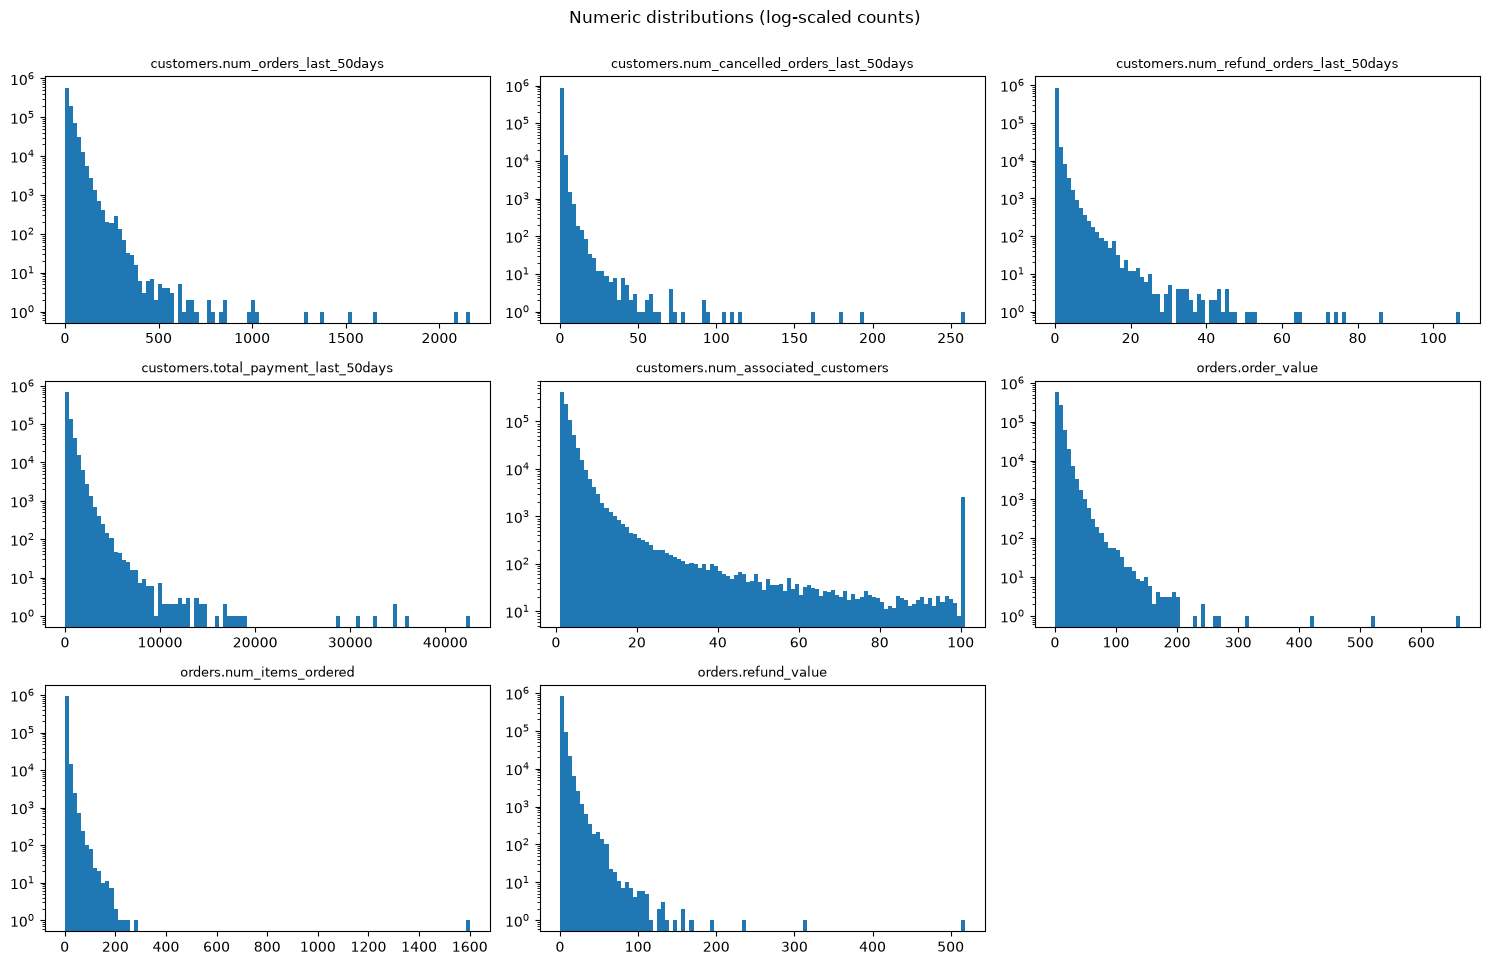

In [14]:
num_cols = [(t, c) for t in raw for c in cols_of(t, {"int", "float"})]
ncols = 3
fig, axes = plt.subplots(int(np.ceil(len(num_cols) / ncols)), ncols, figsize=(15, 3.2 * np.ceil(len(num_cols) / ncols)))
for ax, (t, c) in zip(np.ravel(axes), num_cols):
    x = typed[t][c].dropna()
    ax.hist(x, bins=100, log=True)
    ax.set_title(f"{t}.{c}", fontsize=9)
for ax in np.ravel(axes)[len(num_cols):]:
    ax.axis("off")
fig.suptitle("Numeric distributions (log-scaled counts)", y=1.0)
fig.tight_layout()

## 9. Date / datetime columns
The expected format is checked strictly. Values that fail are tried against `CANDIDATE_DATE_FORMATS`
to find which other formats appear. The **lenient** parse (expected format first, then candidates) is kept
in `typed` for the cross-field checks, so later sections are not blinded by format noise.

In [15]:
date_rows = []
for name, df in raw.items():
    n = len(df)
    for c in cols_of(name, {"datetime"}):
        spec = TABLES[name]["columns"][c]
        s = df[c]
        present = ~is_null_token(s)
        strict = pd.to_datetime(s.where(present), format=spec["format"], errors="coerce")
        nonconform = present & strict.isna()
        lenient = strict.copy()
        alt_formats = {}
        remaining = nonconform.copy()
        for fmt in CANDIDATE_DATE_FORMATS:
            if fmt == spec["format"] or not remaining.any():
                continue
            p = pd.to_datetime(s.where(remaining), format=fmt, errors="coerce")
            hit = remaining & p.notna()
            if hit.any():
                alt_formats[fmt] = int(hit.sum())
                lenient[hit] = p[hit]
                remaining &= ~hit
        unparseable = remaining
        too_early = lenient < MIN_PLAUSIBLE_DATE
        too_late = lenient > MAX_PLAUSIBLE_DATE
        date_rows.append({"table": name, "column": c, "expected_format": spec["format"],
                          "nonconforming": int(nonconform.sum()), "alt_formats_found": alt_formats,
                          "unparseable": int(unparseable.sum()), "min": lenient.min(), "max": lenient.max(),
                          "before_min_plausible": int(too_early.sum()), "after_max_plausible": int(too_late.sum())})
        log_issue(name, c, "date.nonconforming_format", "error", (nonconform & ~unparseable).sum(), n,
                  s[nonconform & ~unparseable], note=f"alt formats: {alt_formats}")
        log_issue(name, c, "date.unparseable", "error", unparseable.sum(), n, s[unparseable])
        log_issue(name, c, "date.before_min_plausible", "warning", too_early.sum(), n, s[too_early],
                  note=f"< {MIN_PLAUSIBLE_DATE.date()}")
        log_issue(name, c, "date.in_future", "error", too_late.sum(), n, s[too_late])
        typed[name][c] = lenient

pd.DataFrame(date_rows)

,table,column,expected_format,nonconforming,alt_formats_found,unparseable,min,max,before_min_plausible,after_max_plausible
0,customers,first_order_datetime,%Y-%m-%d %H:%M:%S,0,{},0,2012-03-25 12:53:43,2023-05-10 20:59:37,0,0
1,orders,order_date,%Y/%m/%d,709,"{'%Y-%m-%d': 200, '%Y/%b/%d': 509}",0,2022-11-12 00:00:00,2023-05-11 00:00:00,0,0


orders.order_date: 181 days, 0 days with zero rows, 0 days < 20% of median volume


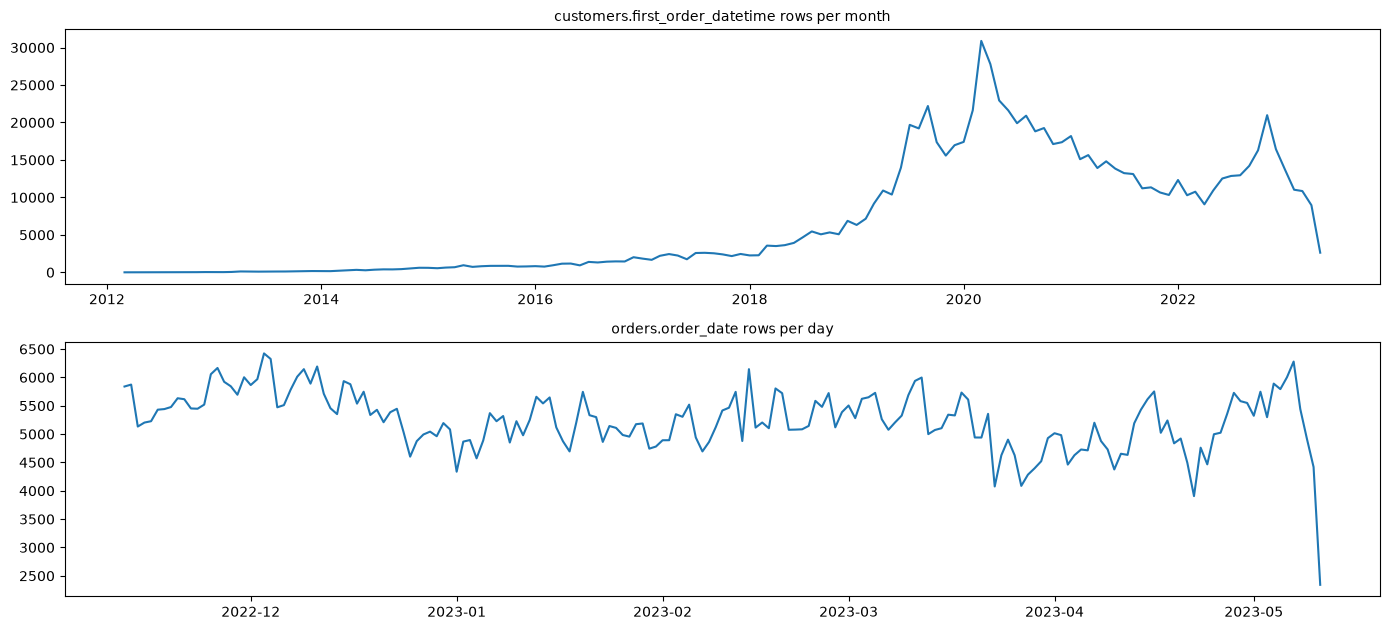

In [16]:
date_cols = [(t, c) for t in raw for c in cols_of(t, {"datetime"})]
fig, axes = plt.subplots(len(date_cols), 1, figsize=(14, 3.2 * len(date_cols)), squeeze=False)
for ax, (t, c) in zip(axes[:, 0], date_cols):
    d = typed[t][c].dropna()
    spec = TABLES[t]["columns"][c]
    freq = "D" if spec.get("daily_continuity") else "MS"
    counts = d.dt.to_period(freq[0]).value_counts().sort_index()
    counts.index = counts.index.to_timestamp()
    ax.plot(counts.index, counts.values)
    ax.set_title(f"{t}.{c} rows per {'day' if freq == 'D' else 'month'}", fontsize=10)
fig.tight_layout()

# Gaps in what should be a continuous daily series (missing extract days / partial loads).
for t, c in date_cols:
    if not TABLES[t]["columns"][c].get("daily_continuity"):
        continue
    d = typed[t][c].dropna().dt.normalize()
    daily = d.value_counts().reindex(pd.date_range(d.min(), d.max(), freq="D"), fill_value=0)
    gaps = daily[daily == 0]
    low = daily[(daily > 0) & (daily < 0.2 * daily.median())]
    print(f"{t}.{c}: {len(daily)} days, {len(gaps)} days with zero rows, {len(low)} days < 20% of median volume")
    log_issue(t, c, "date.missing_days", "warning", len(gaps), len(daily), gaps.index.date)
    log_issue(t, c, "date.low_volume_days", "warning", len(low), len(daily), low.index.date,
              note="possible partial load")

## 10. Duplicates and key uniqueness
* exact duplicate rows
* primary-key duplicates, split into *identical* (safe to drop) and *conflicting* (other fields differ, so a rule is needed)
* whether the key is unique **within country** (composite key), which tells us whether IDs are global or per market

In [17]:
dup_rows = []
key_dups = {}
for name, df in raw.items():
    n = len(df)
    exact = df.duplicated(keep=False)
    log_issue(name, "<row>", "dup.exact_rows", "warning", df.duplicated().sum(), n,
              note="extra copies (first occurrence not counted)")
    pk = [k for k in TABLES[name]["primary_key"] if k in df.columns]
    if not pk:
        continue
    pk_norm = df[pk].apply(lambda s: s.str.strip().str.lower())
    dup_mask = pk_norm.duplicated(keep=False)
    dup_df = df[dup_mask & ~exact]
    key_dups[name] = dup_df.sort_values(pk)
    n_keys = pk_norm[dup_mask].drop_duplicates().shape[0]
    row = {"table": name, "primary_key": pk, "exact_dup_rows": int(df.duplicated().sum()),
           "dup_key_values": n_keys, "rows_with_dup_key_conflicting": len(dup_df)}
    log_issue(name, "+".join(pk), "dup.primary_key_conflicting", "error", len(dup_df), n,
              dup_df[pk[0]], note="same key, different content")
    if GROUP_COL in df.columns and GROUP_COL not in pk:
        comp = pd.concat([pk_norm, df[GROUP_COL].str.strip().str.upper()], axis=1)
        comp_dups = comp.duplicated(keep=False)
        row["dup_keys_within_country"] = int(comp_dups.sum())
        row["dup_keys_across_countries_only"] = int((dup_mask & ~comp_dups).sum())
        log_issue(name, "+".join(pk), "dup.key_reused_across_countries", "warning", (dup_mask & ~comp_dups).sum(), n,
                  df.loc[dup_mask & ~comp_dups, pk[0]],
                  note=f"key unique only per {GROUP_COL}. Decide global vs composite key")
    dup_rows.append(row)

display(pd.DataFrame(dup_rows))
for name, d in key_dups.items():
    if len(d):
        print(f"--- {name}: rows sharing a primary key (first 20)")
        display(d.head(20))

,table,primary_key,exact_dup_rows,dup_key_values,rows_with_dup_key_conflicting,dup_keys_within_country,dup_keys_across_countries_only
0,customers,[customer_id],0,0,0,0,0
1,orders,[order_id],0,3,6,0,6
2,labels,[order_id],0,3,6,0,6


--- orders: rows sharing a primary key (first 20)


,country_code,order_id,collect_type,payment_method,order_value,num_items_ordered,refund_value,order_date
659870,MY,431b5e1fcd,Delivery,online banking,5.418000225163645,1.0,5.62,2023/05/06
821731,PK,431b5e1fcd,Delivery,payment on Delivery,23.789866354814936,19.0,0.92,2022/11/30
575066,BD,8bc3659dde,Delivery,payment on Delivery,2.8296499779570268,1.0,0.0,2022/11/25
864890,TH,8bc3659dde,Delivery,cybersource,1.3904090694715112,1.0,0.0,2023/02/03
46512,PH,ac6b16a277,Delivery,payment on Delivery,8.928004404032965,5.0,0.0,2023/01/04
522731,MY,ac6b16a277,Delivery,payment on Delivery,9.066589298437986,3.0,0.0,2022/12/17


--- labels: rows sharing a primary key (first 20)


,country_code,order_id,customer_id,is_fraud
666815,PK,431b5e1fcd,3d7ad48f9c,0
683871,MY,431b5e1fcd,5d846302c1,0
248428,PH,a4a09bbcbe,5a747496ed,0
258086,MY,a4a09bbcbe,1081c87711,0
241898,MY,ac6b16a277,ee81698ce5,0
742828,PH,ac6b16a277,bb9bd69f57,1


## 11. Referential integrity and coverage
* **Orphans:** child rows whose key is missing from the parent table. Also checks whether normalising (strip/lower) would fix them.
* **Cross-table agreement:** columns that must match across the join (e.g. `country_code`), compared after
  normalisation. Keys duplicated in either table are left out to avoid fan-out.
* **Coverage:** parent rows with no child row.

In [18]:
def norm_key(s):
    return s.str.strip().str.lower()

ri_rows = []
for fk in FOREIGN_KEYS:
    ch, pa = fk["child"], fk["parent"]
    if ch not in raw or pa not in raw:
        continue
    c, p = raw[ch], raw[pa]
    ck, pk_ = c[fk["child_col"]], p[fk["parent_col"]]
    orphan = ~ck.isin(set(pk_))
    orphan_after_norm = ~norm_key(ck).isin(set(norm_key(pk_)))
    ri_rows.append({"relation": f"{ch}.{fk['child_col']} -> {pa}.{fk['parent_col']}",
                    "child_rows": len(c), "orphan_rows": int(orphan.sum()),
                    "orphan_unique_keys": int(ck[orphan].nunique()),
                    "orphans_fixed_by_normalising": int((orphan & ~orphan_after_norm).sum())})
    log_issue(ch, fk["child_col"], "ri.orphan_foreign_key", "error", orphan_after_norm.sum(), len(c),
              ck[orphan_after_norm], note=f"not found in {pa}.{fk['parent_col']}")
    log_issue(ch, fk["child_col"], "ri.orphan_fixed_by_normalising", "warning", (orphan & ~orphan_after_norm).sum(), len(c),
              ck[orphan & ~orphan_after_norm])

    # Columns that must agree across the join (one-to-one keys only).
    p_unique = p[~norm_key(pk_).duplicated(keep=False)]
    c_cols = [fk["child_col"]] + [x for x in fk["compare"] if x in c.columns]
    p_cols = [fk["parent_col"]] + [x for x in fk["compare"] if x in p.columns]
    m = (c[c_cols].assign(_k=norm_key(ck))
         .merge(p_unique[p_cols].assign(_k=norm_key(p_unique[fk["parent_col"]])),
                on="_k", suffixes=("_child", "_parent")))
    for col in fk["compare"]:
        if f"{col}_child" not in m:
            continue
        a, b = m[f"{col}_child"], m[f"{col}_parent"]
        raw_diff = a != b
        real_diff = a.str.strip().str.upper() != b.str.strip().str.upper()
        log_issue(ch, col, f"ri.{col}_mismatch_vs_{pa}", "error", real_diff.sum(), len(m),
                  (a[real_diff] + "≠" + b[real_diff]), note="values differ after normalisation")
        log_issue(ch, col, f"ri.{col}_case_mismatch_vs_{pa}", "info", (raw_diff & ~real_diff).sum(), len(m),
                  (a[raw_diff & ~real_diff] + "≠" + b[raw_diff & ~real_diff]), note="differs only in case/whitespace")
        ri_rows[-1][f"{col}_mismatch"] = int(real_diff.sum())

for cov in COVERAGE:
    pa, ch = cov["parent"], cov["child"]
    if ch not in raw or pa not in raw:
        continue
    pk_ = raw[pa][cov["parent_col"]]
    uncovered = ~norm_key(pk_).isin(set(norm_key(raw[ch][cov["child_col"]])))
    ri_rows.append({"relation": f"{pa}.{cov['parent_col']} without {ch}", "child_rows": len(raw[pa]),
                    "orphan_rows": int(uncovered.sum())})
    log_issue(pa, cov["parent_col"], f"ri.no_matching_{ch}", "error" if cov["expected_full"] else "info",
              uncovered.sum(), len(raw[pa]), pk_[uncovered])

pd.DataFrame(ri_rows)

,relation,child_rows,orphan_rows,orphan_unique_keys,orphans_fixed_by_normalising,country_code_mismatch
0,labels.order_id -> orders.order_id,950318,443,443.0,0.0,1.0
1,labels.customer_id -> customers.customer_id,950318,14,14.0,0.0,0.0
2,orders.order_id without labels,949889,14,NaN,NaN,NaN
3,customers.customer_id without labels,901312,279054,NaN,NaN,NaN


## 12. Logical consistency rules
Row-level rules inside a table plus cross-table temporal rules. Each rule returns a boolean mask
of **violations**, worked out from the typed (lenient) values. Add new rules to the lists below.

In [19]:
T = typed  # shorthand

ROW_RULES = [
    # (table, rule name, severity, function(typed_df) -> violation mask, note)
    ("customers", "cancelled_gt_orders", "error",
     lambda d: d.num_cancelled_orders_last_50days > d.num_orders_last_50days, ""),
    ("customers", "refunded_gt_orders", "error",
     lambda d: d.num_refund_orders_last_50days > d.num_orders_last_50days, ""),
    ("customers", "payment_without_orders", "warning",
     lambda d: (d.num_orders_last_50days == 0) & (d.total_payment_last_50days > 0), ""),
    ("customers", "orders_without_payment", "info",
     lambda d: (d.num_orders_last_50days > 0) & (d.total_payment_last_50days == 0), "could be all-cancelled. Confirm"),
    ("orders", "refund_gt_order_value", "warning",
     lambda d: d.refund_value > d.order_value + 1e-9, "check whether refund_value and order_value share a unit/currency/scale"),
    ("orders", "zero_order_value", "warning", lambda d: d.order_value == 0, ""),
    ("orders", "refund_value_nonzero", "info", lambda d: d.refund_value > 0,
     "share of orders with a refund. If implausibly high, the column's meaning or unit needs confirming"),
]

rule_rows = []
for table, rule, sev, fn, note in ROW_RULES:
    if table not in T:
        continue
    try:
        mask = fn(T[table]).fillna(False)
    except (AttributeError, KeyError) as e:
        print(f"skip {table}.{rule}: missing column {e}")
        continue
    rule_rows.append({"table": table, "rule": rule, "severity": sev, "violations": int(mask.sum()),
                      "pct": round(100 * mask.mean(), 4)})
    log_issue(table, "<row>", f"rule.{rule}", sev, mask.sum(), len(mask),
              raw[table].index[mask].map(lambda i: f"row {i}"), note=note)

# Cross-table: an order dated before the customer's first-order timestamp.
needed = {"labels": ["order_id", "customer_id"], "orders": ["order_id", "order_date", ],
          "customers": ["customer_id", "first_order_datetime", "num_orders_last_50days"]}
if all(t in raw and all(c in raw[t].columns for c in cs) for t, cs in needed.items()):
    link = (raw["labels"][["order_id", "customer_id"]]
            .drop_duplicates("order_id", keep=False)
            .merge(pd.DataFrame({"order_id": raw["orders"]["order_id"], "order_date": T["orders"]["order_date"]})
                   .drop_duplicates("order_id", keep=False), on="order_id")
            .merge(pd.DataFrame({"customer_id": raw["customers"]["customer_id"],
                                 "first_order": T["customers"]["first_order_datetime"]}), on="customer_id"))
    early = link.order_date < link.first_order.dt.normalize()
    rule_rows.append({"table": "orders×customers", "rule": "order_before_customer_first_order", "severity": "warning",
                      "violations": int(early.sum()), "pct": round(100 * early.mean(), 4)})
    log_issue("orders", "order_date", "rule.order_before_customer_first_order", "warning", early.sum(), len(link),
              link.loc[early, "order_id"], note="order_date < customers.first_order_datetime")

    # The "last 50 days" aggregates should cover at least the orders we can see in the labels table
    # for that customer in the last 50 days of the extract.
    end = link.order_date.max()
    recent = link[link.order_date > end - pd.Timedelta(days=50)]
    seen = recent.groupby("customer_id").size().rename("orders_seen")
    agg = pd.DataFrame({"customer_id": raw["customers"]["customer_id"],
                        "num_orders_last_50days": T["customers"]["num_orders_last_50days"]}).merge(seen, on="customer_id")
    under = agg.num_orders_last_50days < agg.orders_seen
    rule_rows.append({"table": "customers×orders", "rule": "agg_orders_lt_orders_seen_last50d", "severity": "info",
                      "violations": int(under.sum()), "pct": round(100 * under.mean(), 4)})
    log_issue("customers", "num_orders_last_50days", "rule.agg_orders_lt_orders_seen_last50d", "info", under.sum(), len(agg),
              agg.loc[under, "customer_id"],
              note=f"window assumed to end {end.date()}. The real reference date is unknown, so treat as a pointer")

else:
    print("Skipping cross-table rules: required tables/columns missing", needed)

pd.DataFrame(rule_rows)

,table,rule,severity,violations,pct
0,customers,cancelled_gt_orders,error,0,0.0000
1,customers,refunded_gt_orders,error,0,0.0000
2,customers,payment_without_orders,warning,28556,3.1683
3,customers,orders_without_payment,info,4817,0.5344
4,orders,refund_gt_order_value,warning,199687,21.0221
5,orders,zero_order_value,warning,23,0.0024
6,orders,refund_value_nonzero,info,581947,61.2647
7,orders×customers,order_before_customer_first_order,warning,105,0.0111
8,customers×orders,agg_orders_lt_orders_seen_last50d,info,14023,7.0937


### Systematic missingness / invalid values by group
If missing or invalid values are concentrated in one group (country), that usually points to an upstream
source or market-specific extraction problem rather than random noise.

In [20]:
for name, df in raw.items():
    if GROUP_COL not in df.columns:
        continue
    g = df[GROUP_COL].str.strip().str.upper()
    flags = pd.DataFrame({c: is_null_token(df[c]) for c in cols_of(name) if c != GROUP_COL})
    flags = flags.loc[:, flags.any()]
    if flags.empty:
        continue
    rate = flags.groupby(g).mean().mul(100).round(3)
    print(f"--- {name}: % missing by {GROUP_COL}")
    display(rate)
    for c in flags:
        share = flags[c].groupby(g).sum() / flags[c].sum()
        if share.max() > 0.9 and g.nunique() > 1:
            log_issue(name, c, "missing.concentrated_in_group", "warning", flags[c].sum(), len(df),
                      [share.idxmax()], note=f"{share.max():.0%} of missing values in {GROUP_COL}={share.idxmax()}")

# Category availability by group: values that only occur in one group are worth knowing for mapping tables.
for name, df in raw.items():
    if GROUP_COL not in df.columns:
        continue
    for c in cols_of(name, {"category"}):
        if c == GROUP_COL or c == "is_fraud" or df[c].nunique() > 50:
            continue
        print(f"--- {name}.{c} by {GROUP_COL}")
        display(pd.crosstab(df[c].replace("", "<empty>"), df[GROUP_COL]))

--- customers: % missing by country_code


,first_order_datetime
country_code,
BD,0.104
MY,0.098
PH,0.040
PK,0.080
TH,0.127


--- orders: % missing by country_code


,payment_method,num_items_ordered
country_code,,
BD,0.000,0.002
MY,5.963,0.000
PH,0.000,0.000
PK,0.000,0.000
TH,0.000,0.000


--- orders.collect_type by country_code


country_code,BD,MY,PH,PK,TH
collect_type,,,,,
Delivery,56621,356854,278315,182442,63498
delivery,0,52,33,0,0
pickup,2939,3663,2863,2380,229


--- orders.payment_method by country_code


country_code,BD,MY,PH,PK,TH
payment_method,,,,,
<empty>,0,21501,0,0,0
Online Banking,0,103,0,0,0
adyen hpp molpay,0,837,0,0,0
antfinancial bkash,17889,0,0,0,0
antfinancial gcash,0,0,102657,0,0
antfinancial truemoney,0,0,0,0,9294
balance,465,0,16088,9383,0
boost wallet,0,6088,0,0,0
credit card,9807,31136,59239,13559,501


## 13. Drift vs baseline profile
Builds a compact profile of this dataset. On the **first run** (or `SAVE_AS_BASELINE=True`) it is saved as the
baseline. On later runs with new data it is compared against the baseline:
new or vanished columns, new category values, missing-rate shifts and range shifts.

In [21]:
def build_profile():
    prof = {"run_tag": RUN_TAG, "tables": {}}
    for name, df in raw.items():
        tp = {"rows": len(df), "columns": list(df.columns), "cols": {}}
        for c in cols_of(name):
            kind = TABLES[name]["columns"][c]["kind"]
            cp = {"kind": kind, "missing_pct": float(is_null_token(df[c]).mean() * 100)}
            if kind in ("category", "bool"):
                cp["values"] = sorted(df[c][~is_null_token(df[c])].unique().tolist())
            elif kind in ("int", "float"):
                x = typed[name][c].dropna()
                cp.update({k: float(v) for k, v in x.quantile([0.01, 0.5, 0.99]).rename(lambda q: f"q{q}").items()})
                cp["max"] = float(x.max()) if len(x) else None
            elif kind == "datetime":
                x = typed[name][c].dropna()
                cp.update(min=str(x.min()), max=str(x.max()))
            tp["cols"][c] = cp
        prof["tables"][name] = tp
    return prof

profile = build_profile()
(OUTPUT_DIR / f"profile_{RUN_TAG}.json").write_text(json.dumps(profile, indent=1, default=str))

if SAVE_AS_BASELINE:
    BASELINE_PROFILE.write_text(json.dumps(profile, indent=1, default=str))
    print(f"Saved baseline profile -> {BASELINE_PROFILE}")
else:
    base = json.loads(BASELINE_PROFILE.read_text())
    drift = []
    for name, tp in profile["tables"].items():
        bt = base["tables"].get(name)
        if bt is None:
            continue
        for c in set(bt["columns"]) ^ set(tp["columns"]):
            drift.append((name, c, "column added" if c in tp["columns"] else "column removed", ""))
        for c, cp in tp["cols"].items():
            bc = bt["cols"].get(c)
            if bc is None:
                continue
            if abs(cp["missing_pct"] - bc["missing_pct"]) > 1:
                drift.append((name, c, "missing_pct shift", f"{bc['missing_pct']:.2f}% -> {cp['missing_pct']:.2f}%"))
            if "values" in cp:
                new = sorted(set(cp["values"]) - set(bc["values"]))
                if new:
                    drift.append((name, c, "new category values", new[:10]))
            if "q0.5" in cp and bc.get("q0.5"):
                for q in ("q0.01", "q0.5", "q0.99"):
                    if bc[q] and abs(cp[q] - bc[q]) / abs(bc[q]) > 0.5:
                        drift.append((name, c, f"{q} shift >50%", f"{bc[q]:.3f} -> {cp[q]:.3f}"))
    drift_df = pd.DataFrame(drift, columns=["table", "column", "drift", "detail"])
    for r in drift_df.itertuples():
        log_issue(r.table, r.column, f"drift.{r.drift.replace(' ', '_')}", "warning", 1,
                  note=f"{r.detail} (vs baseline {base['run_tag']})")
    display(drift_df if len(drift_df) else "No drift vs baseline.")

Saved baseline profile -> ../eda_output/baseline_profile.json


## 14. Issue summary
This is the hand-off to the cleaning pipeline: one row per (table, column, check). It is saved as CSV so runs
on different data drops can be diffed.

In [22]:
SEV_ORDER = {"error": 0, "warning": 1, "info": 2}
issues = (pd.DataFrame(ISSUES, columns=["table", "column", "check", "severity", "n_rows", "pct", "examples", "note"])
          .sort_values(["severity", "table", "n_rows"], key=lambda s: s.map(SEV_ORDER) if s.name == "severity" else s,
                       ascending=[True, True, False])
          .reset_index(drop=True))
out = OUTPUT_DIR / f"issues_{RUN_TAG}.csv"
issues.to_csv(out, index=False)
print(f"{len(issues)} findings -> {out}")
print(issues.severity.value_counts().to_string())
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 70):
    display(issues)

38 findings -> ../eda_output/issues_20261026_105627.csv
severity
error      14
info       14
warning    10


,table,column,check,severity,n_rows,pct,examples,note
0,customers,first_order_datetime,missing.empty,error,712,0.0790,,
1,customers,country_code,domain.not_allowed_exact,error,390,0.0433,"'my', 'pk'",valid after case/whitespace normalisation
2,customers,mobile_verified,domain.not_allowed_at_all,error,165,0.0183,'yes',"unknown value, needs a mapping rule or rejection"
3,labels,order_id,ri.orphan_foreign_key,error,443,0.0466,"'4099f2c800', '55ca05041e', '46cee8e9d1', 'd0352c8a8a', '858ac366d5'",not found in orders.order_id
4,labels,country_code,domain.not_allowed_exact,error,301,0.0317,"'my', 'ph'",valid after case/whitespace normalisation
5,labels,customer_id,ri.orphan_foreign_key,error,14,0.0015,"'ff3eeee889', '0730ee04b6', 'cb7eeeebfe', 'e89eaaaada', '024dddd314'",not found in customers.customer_id
6,labels,order_id,dup.primary_key_conflicting,error,6,0.0006,"'ac6b16a277', 'a4a09bbcbe', '431b5e1fcd'","same key, different content"
7,labels,country_code,ri.country_code_mismatch_vs_orders,error,1,0.0001,'MY≠PH',values differ after normalisation
8,orders,payment_method,missing.empty,error,21501,2.2635,,
9,orders,collect_type,domain.not_allowed_exact,error,12159,1.2800,"'pickup', 'delivery'",valid after case/whitespace normalisation


## 15. Notes from the base sample (run 2026-10-26). Implications for the cleaning pipeline
*These are fixed notes from the first run on `*_base.csv`. On new data, use the summary table above as the source of truth.*

| Area | Finding on base sample | Suggested pipeline step |
|---|---|---|
| `country_code` | lowercase `my`/`pk`/`ph` in customers (390) and labels (301) | `str.strip().str.upper()`, then check against the allowed list |
| `collect_type` | `Delivery` / `delivery` / `pickup` | normalise case into a canonical mapping (`Delivery`, `Pickup`) |
| `payment_method` | 21.5k empty, **all in MY**. Case variants (`Online Banking`, `payment on delivery`). Possible synonym `on Delivery` ≈ `payment on Delivery` | lower-case + mapping table. Ask the source why MY payment method is blank. Keep it as an explicit `unknown` |
| `mobile_verified` | `yes` (165) alongside `True`/`False` | map `{True, yes} → True`, `{False, no} → False`. Reject anything else |
| `order_date` | mixed formats: `%Y/%m/%d`, `%Y-%m-%d` (200), `%Y/%b/%d` (509) | parse with an explicit list of formats. Never use free inference (to avoid day/month swaps) |
| `first_order_datetime` | 712 empty | keep as NaT plus a flag. Do not impute |
| `num_items_ordered` | stored as float (`4.0`), 1 empty, max 1600 | cast to `Int64`. Decide a cap/flag for extreme quantities |
| `num_associated_customers` | spike at exactly 100/101 | probably an upstream cap. Treat ≥100 as censored |
| `refund_value` vs `order_value` | refund > order value on ~21% of orders, refund > 0 on ~61%, refund rounded to 2 dp while order_value is not | **confirm meaning/unit with the data owner** before any rule |
| `order_id` keys | 3 order_ids reused across countries in orders, 3 in labels (not all the same ids) | decide whether the key is global or `(country_code, order_id)`. Join on the composite key |
| Referential integrity | 443 label orders not in orders, 14 orders without labels, 14 label customer_ids not in customers (IDs look corrupted, e.g. `ff3eeee889`) | quarantine orphans in a reject table instead of dropping them silently |
| Aggregates | `num_orders=0` with `total_payment>0` (28.5k). 105 orders dated before the customer's first order | flag these. Confirm the window/reference date of the `_last_50days` fields |

In [23]:
# Compact view: number of distinct checks failing per table and severity.
issues.pivot_table(index="table", columns="severity", values="check", aggfunc="count", fill_value=0)

severity,error,info,warning
table,,,
customers,3,6,2
labels,5,2,1
orders,6,6,7
